In [1]:
pip install fastcore


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install fastai


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from fastcore.all import *
import time
from fastai.vision.all import *
import pandas as pd
import numpy as np
import os 


In [4]:
searches='Glaucoma', 'Cataracts', 'Uveitis', 'Crossed_Eyes', 'Bulging eyes'
path='/Users/bishanbhandari/Desktop/Git/Deep-Learning-and-Computer-Vision/Eye_Disease_Detection/Augmented Dataset'
data_dir_list=os.listdir(path)
print(data_dir_list)

['Glaucoma', '.DS_Store', 'Cataracts', 'Uveitis', 'Crossed_Eyes', 'Bulging eyes']


In [5]:
# removing the .DS_Store from the list 
data_dir_list.remove('.DS_Store')
print(data_dir_list)

['Glaucoma', 'Cataracts', 'Uveitis', 'Crossed_Eyes', 'Bulging eyes']


In [6]:
get_items=get_image_files(path)

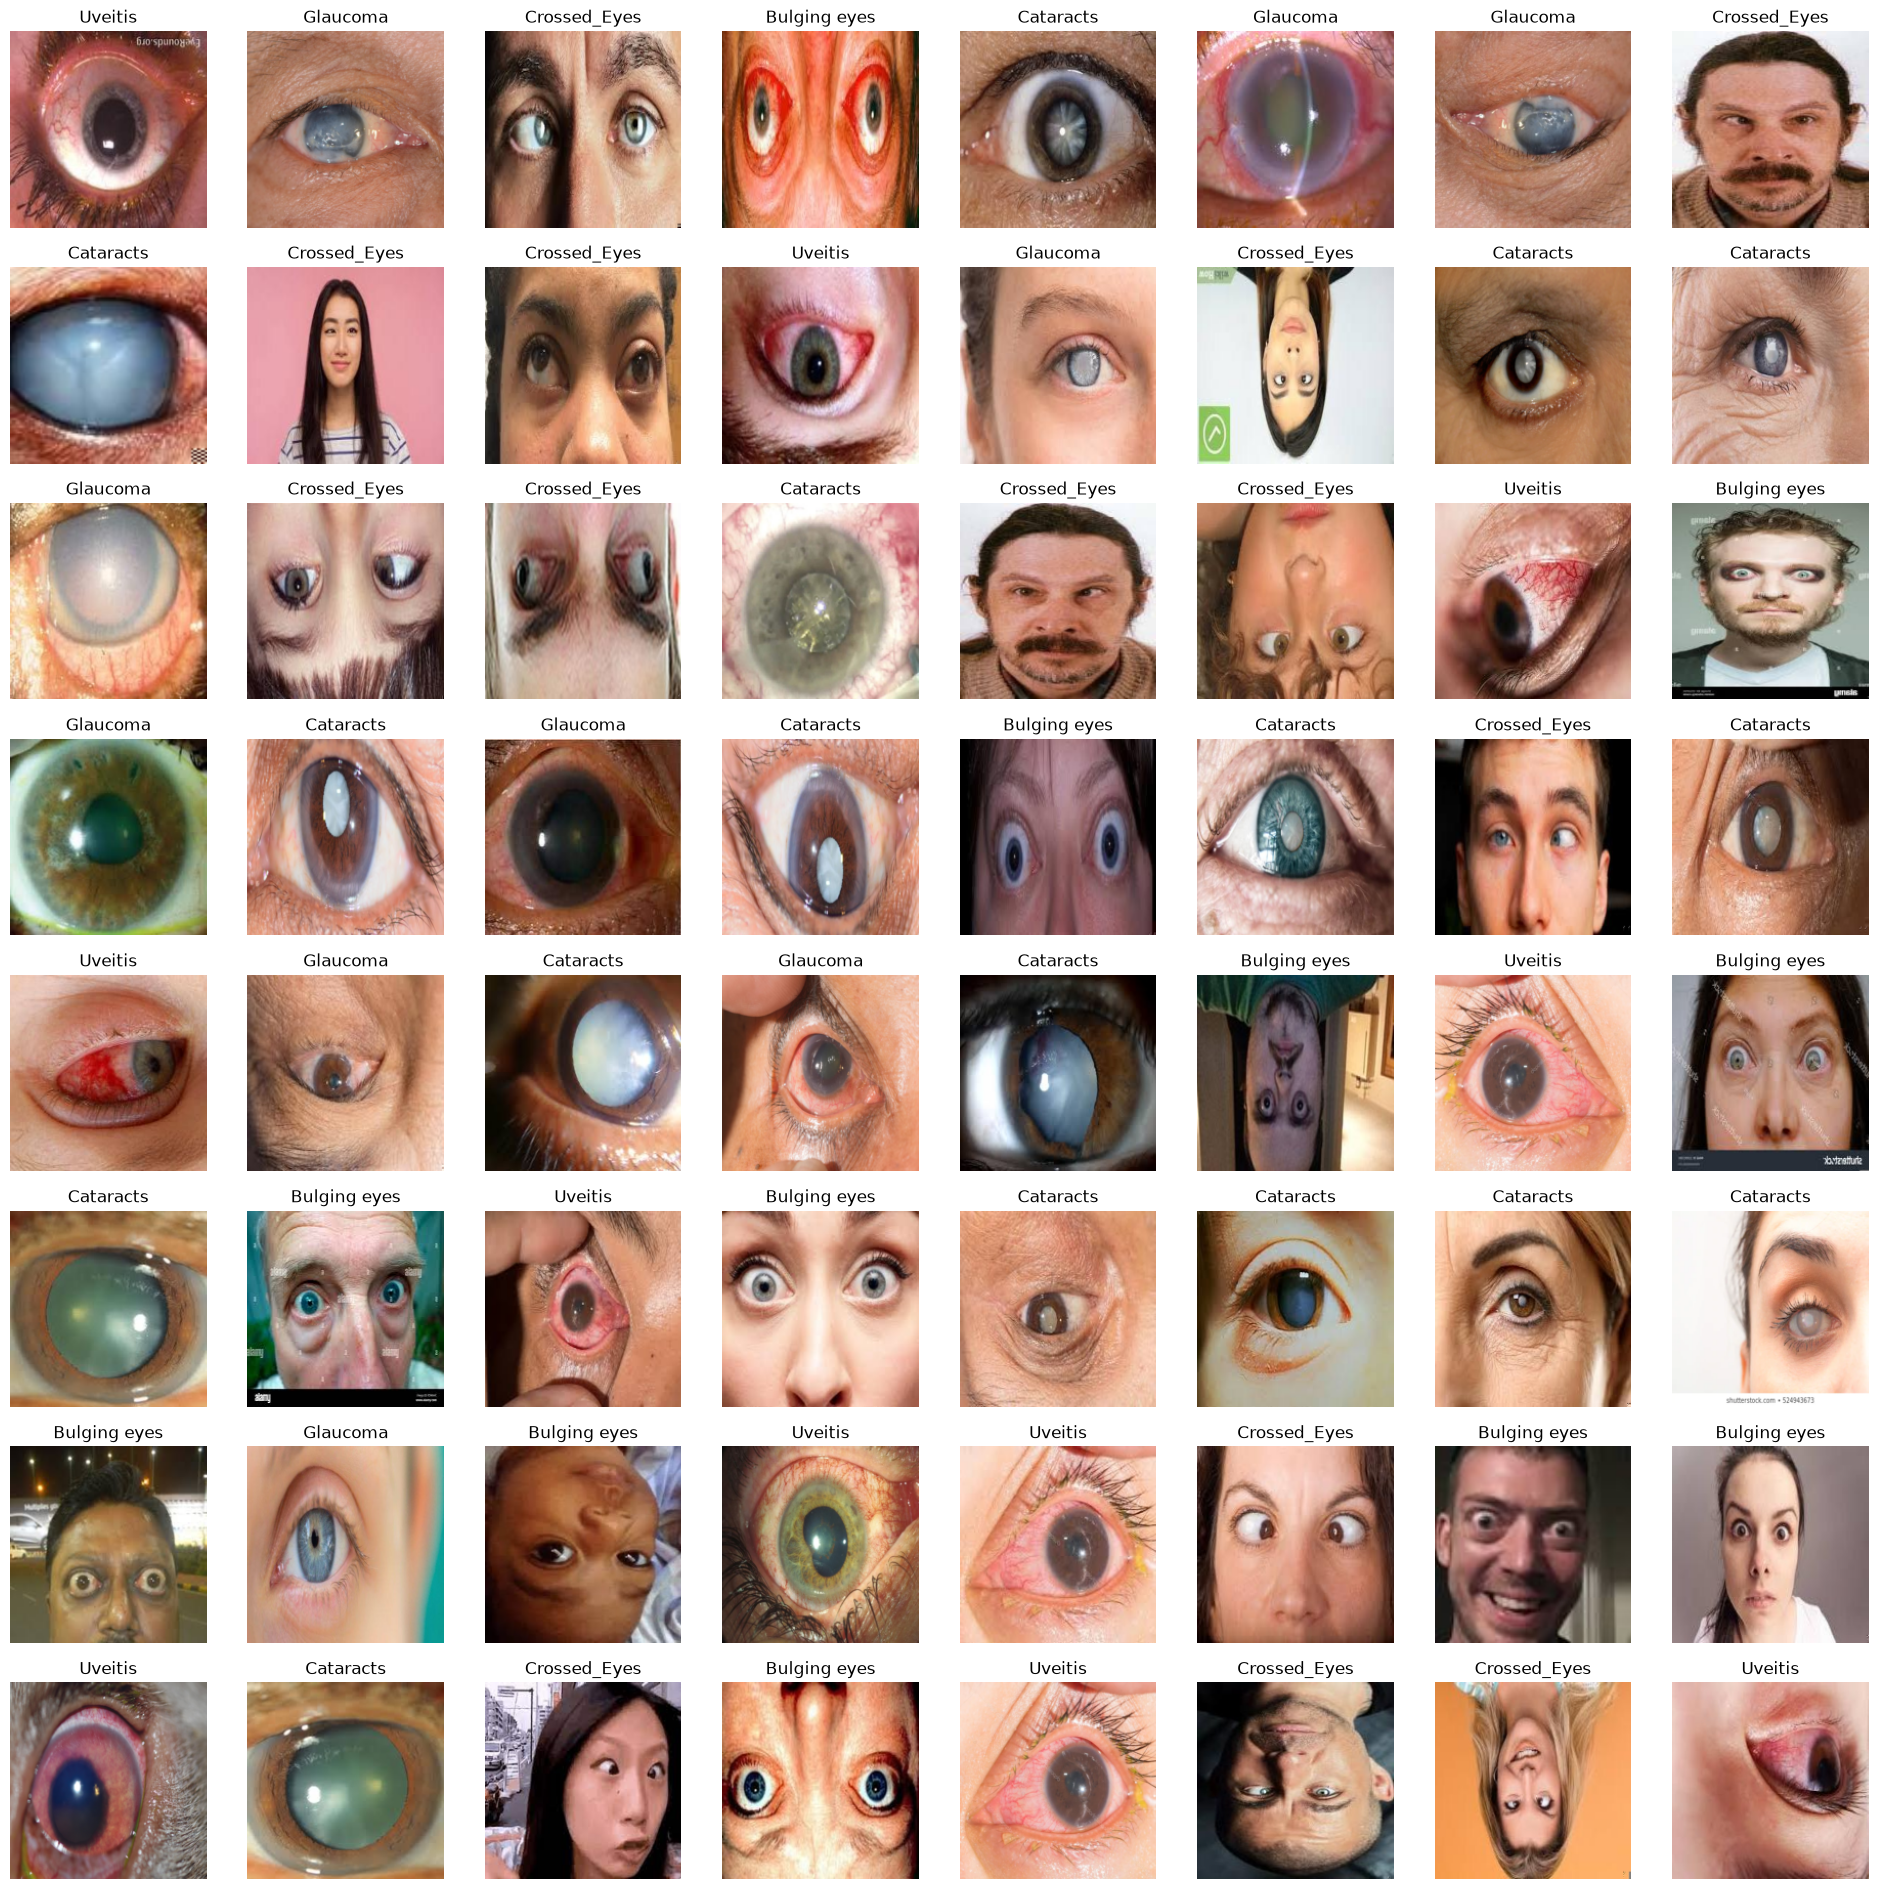

In [7]:
import torch

dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, device=torch.device("cpu"))

dls.show_batch(max_n=100)

In [8]:
dls.vocab

['Bulging eyes', 'Cataracts', 'Crossed_Eyes', 'Glaucoma', 'Uveitis']

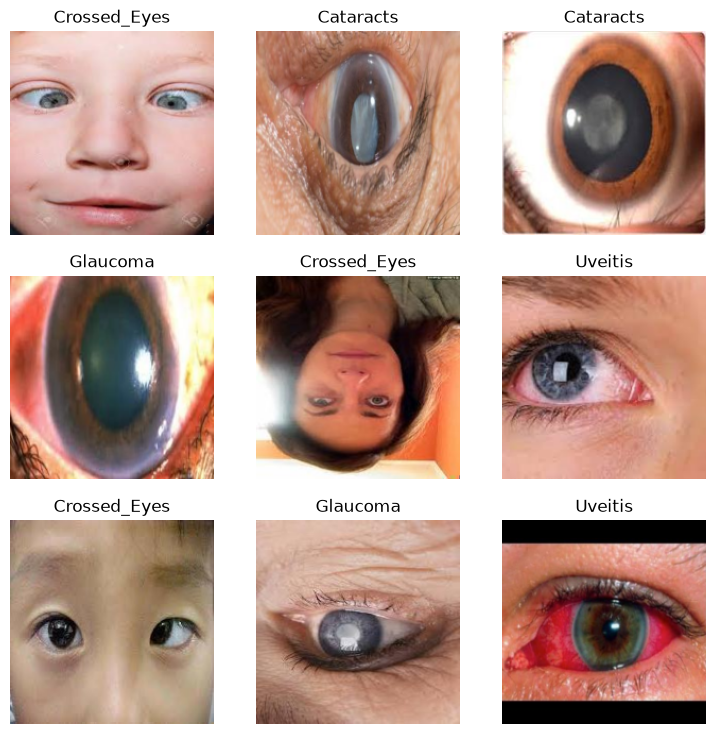

In [9]:
blocks= (ImageBlock,CategoryBlock),
get_items=get_image_files,
splitter=RandomSplitter(valid_pct=0.2,seed=42)
dls.show_batch()

In [10]:
import sys
import ssl
import certifi
import os

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("OpenSSL version:", ssl.OPENSSL_VERSION)

print("\nDefault SSL paths:")
print(ssl.get_default_verify_paths())

print("\nCertifi certificate path:")
print(certifi.where())

print("\nSSL environment variables:")
print("SSL_CERT_FILE:", os.environ.get("SSL_CERT_FILE"))
print("REQUESTS_CA_BUNDLE:", os.environ.get("REQUESTS_CA_BUNDLE"))

Python executable: /usr/local/bin/python3
Python version: 3.13.3 (v3.13.3:6280bb54784, Apr  8 2025, 10:47:54) [Clang 15.0.0 (clang-1500.3.9.4)]
OpenSSL version: OpenSSL 3.0.16 11 Feb 2025

Default SSL paths:
DefaultVerifyPaths(cafile='/Library/Frameworks/Python.framework/Versions/3.13/etc/openssl/cert.pem', capath=None, openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='/Library/Frameworks/Python.framework/Versions/3.13/etc/openssl/cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='/Library/Frameworks/Python.framework/Versions/3.13/etc/openssl/certs')

Certifi certificate path:
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/certifi/cacert.pem

SSL environment variables:
SSL_CERT_FILE: None
REQUESTS_CA_BUNDLE: None


In [11]:
import urllib.request
import ssl
import certifi

context = ssl.create_default_context(cafile=certifi.where())

try:
    response = urllib.request.urlopen(
        "https://www.google.com",
        context=context,
        timeout=15
    )
    print("Connection successful:", response.status)

except Exception as e:
    print(type(e).__name__, e)

Connection successful: 200


In [15]:
learn = vision_learner(dls, resnet34, metrics=accuracy)
learn.fine_tune(5)

epoch,train_loss,valid_loss,accuracy,time
0,2.170385,0.989116,0.680272,00:28


epoch,train_loss,valid_loss,accuracy,time
0,0.795480,0.464615,0.795918,00:40
1,0.528225,0.426858,0.843537,00:40
2,0.353431,0.360858,0.891156,00:41
3,0.256044,0.339125,0.904762,00:41
4,0.199001,0.340157,0.897959,00:42


In [16]:
learn.summary()

<div></div>

Sequential (Input shape: 64 x 3 x 192 x 192)
Layer (type)         Output Shape         Param #    Trainable 
                     64 x 64 x 96 x 96   
Conv2d                                    9408       True      
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     64 x 64 x 48 x 48   
MaxPool2d                                                      
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
ReLU                      

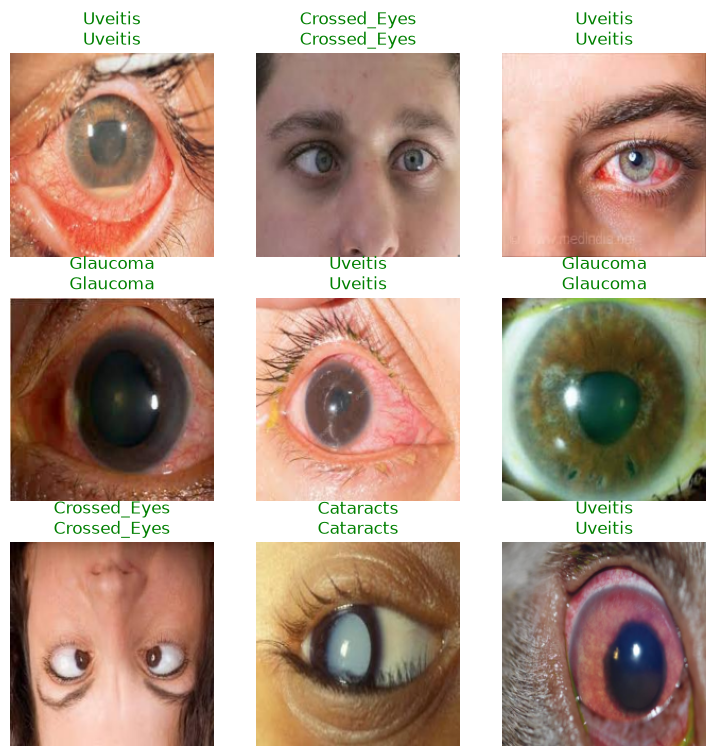

In [17]:
learn.show_results()

<div></div>

SuggestedLRs(valley=6.30957365501672e-05)

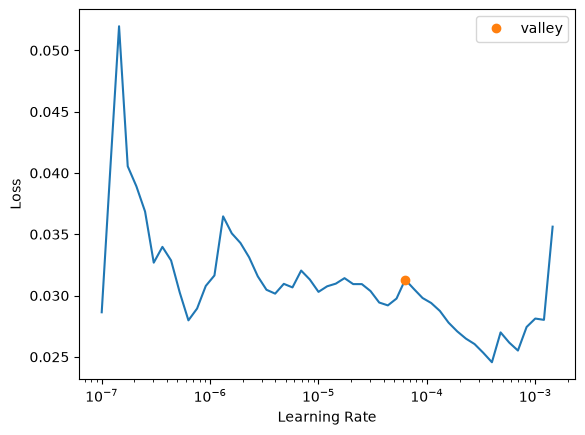

In [18]:
learn.lr_find()

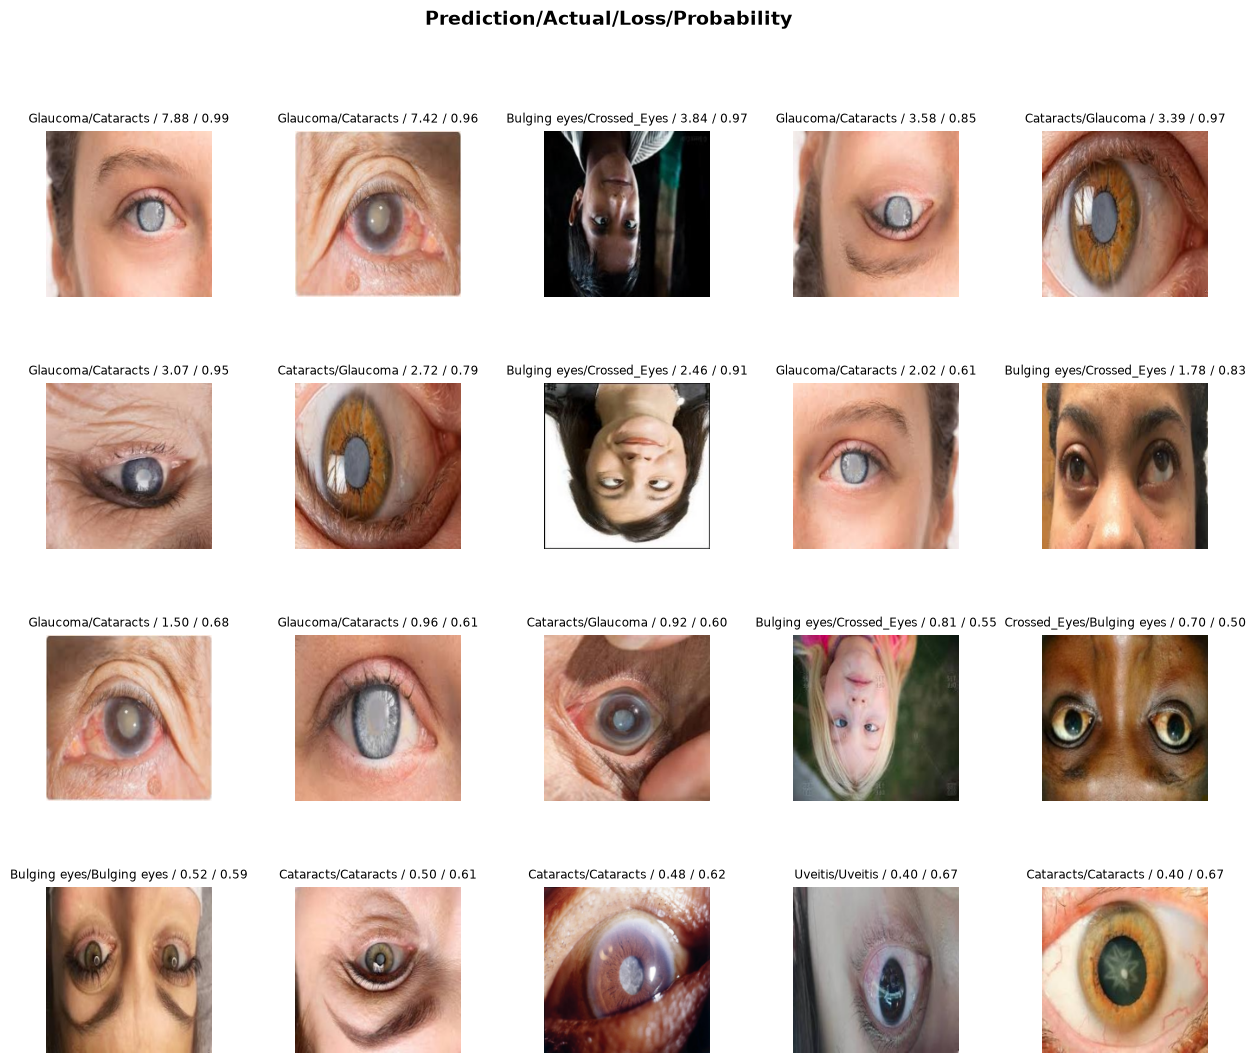

In [19]:
import matplotlib.pyplot as plt
plt.rcParams['font.size']=7

interp=ClassificationInterpretation.from_learner(learn)
interp.plot_top_losses(20)
plt.subplots_adjust(hspace=0.5,wspace=0.5)
plt.show()